In [1]:
from one.api import ONE
from brainbox.io.one import SessionLoader
from pprint import pprint
import one.alf.io as alfio

from brainwidemap import bwm_query, load_good_units, load_trials_and_mask, bwm_units

In [2]:
one = ONE(base_url='https://openalyx.internationalbrainlab.org', silent=True)

In [3]:
bwm_df = bwm_query(one)
bwm_df

Loading bwm_query results from fixtures/2023_12_bwm_release.csv


,pid,eid,probe_name,session_number,date,subject,lab
0,56f2a378-78d2-4132-b3c8-8c1ba82be598,6713a4a7-faed-4df2-acab-ee4e63326f8d,probe00,1,2020-02-18,NYU-11,angelakilab
1,47be9ae4-290f-46ab-b047-952bc3a1a509,56956777-dca5-468c-87cb-78150432cc57,probe01,1,2020-02-21,NYU-11,angelakilab
2,6be21156-33b0-4f70-9a0f-65b3e3cd6d4a,56956777-dca5-468c-87cb-78150432cc57,probe00,1,2020-02-21,NYU-11,angelakilab
3,8dfb86c8-d45c-46c4-90ec-33078014d434,4364a246-f8d7-4ce7-ba23-a098104b96e4,probe01,1,2020-01-20,NYU-12,angelakilab
4,c893c0a3-5597-49cf-baa1-60efdfdef542,b182b754-3c3e-4942-8144-6ee790926b58,probe01,1,2020-01-21,NYU-12,angelakilab
...,...,...,...,...,...,...,...
694,8bf0f1a4-0d8c-4df3-a99e-f7c81c809652,993c7024-0abc-4028-ad30-d397ad55b084,probe01,1,2020-09-16,CSH_ZAD_029,zadorlab
695,5d570bf6-a4c6-4bf1-a14b-2c878c84ef0e,fece187f-b47f-4870-a1d6-619afe942a7d,probe01,1,2020-09-17,CSH_ZAD_029,zadorlab
696,f7c93877-ec05-4091-a003-e69fae0f2fa8,fece187f-b47f-4870-a1d6-619afe942a7d,probe00,1,2020-09-17,CSH_ZAD_029,zadorlab
697,675952a4-e8b3-4e82-a179-cc970d5a8b01,c7bd79c9-c47e-4ea5-aea3-74dda991b48e,probe01,1,2020-09-19,CSH_ZAD_029,zadorlab


In [90]:
#bwm_df = bwm_df.head(10)
#bwm_df

In [4]:
import numpy as np

all_units = []
for pid in bwm_df.pid:
    try:
        spikes, clusters = load_good_units(one, pid, compute_metrics=False)

        for _, row in clusters.iterrows():
            cluster_id = row["cluster_id"]

            cluster_index = row.name
            

            spike_times = spikes["times"][spikes["clusters"] == cluster_index]
            spike_voltage = spikes["amps"][spikes["clusters"] == cluster_index]

            unit_dict = {
                "pid": pid,
                "cluster_id": cluster_id,
                "x": row["x"],
                "y": row["y"],
                "z": row["z"],
                "atlas_id": row["atlas_id"],
                "spike_times": spike_times,      
                "spike_voltage": spike_voltage   
            }
            all_units.append(unit_dict)

    except Exception as e:
        print(f"skip {pid}, error: {e}")
        continue

100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.15it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 4/4.0 [00:03<00:00,  1.31it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.28it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.49it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.17it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.38it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.05it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████| 3/3.0 [00:02<00:00,  1.40it/s]


In [5]:
all_units

[{'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 2,
  'x': -0.002289,
  'y': -0.002537,
  'z': -0.003595,
  'atlas_id': 549,
  'spike_times': array([1280.17956115, 1308.40397292, 1408.93956308, ..., 4687.2943644 ,
         4688.31736358, 4688.35463022]),
  'spike_voltage': array([7.00786186e-05, 7.97781831e-05, 7.22701807e-05, ...,
         8.15545573e-05, 7.05181228e-05, 7.70979532e-05])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 15,
  'x': -0.002289,
  'y': -0.002533,
  'z': -0.003576,
  'atlas_id': 549,
  'spike_times': array([   7.27930925,   10.02560684,   10.05437348, ..., 4688.53469674,
         4688.60163002, 4688.63716332]),
  'spike_voltage': array([0.00033245, 0.00033308, 0.00031968, ..., 0.00031284, 0.00034012,
         0.00033704])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 22,
  'x': -0.002289,
  'y': -0.002528,
  'z': -0.003556,
  'atlas_id': 549,
  'spike_times': array([ 219.74047516,  556.91181808,  593.60

In [6]:
import pickle

with open("all_units.pkl", "wb") as f:
    pickle.dump(all_units, f)
print("all_units have been saved in all_units.pkl")

all_units have been saved in all_units.pkl


In [1]:
import pickle

with open("all_units.pkl", "rb") as f:
    all_units = pickle.load(f)

all_units

[{'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 2,
  'x': -0.002289,
  'y': -0.002537,
  'z': -0.003595,
  'atlas_id': 549,
  'spike_times': array([1280.17956115, 1308.40397292, 1408.93956308, ..., 4687.2943644 ,
         4688.31736358, 4688.35463022]),
  'spike_voltage': array([7.00786186e-05, 7.97781831e-05, 7.22701807e-05, ...,
         8.15545573e-05, 7.05181228e-05, 7.70979532e-05])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 15,
  'x': -0.002289,
  'y': -0.002533,
  'z': -0.003576,
  'atlas_id': 549,
  'spike_times': array([   7.27930925,   10.02560684,   10.05437348, ..., 4688.53469674,
         4688.60163002, 4688.63716332]),
  'spike_voltage': array([0.00033245, 0.00033308, 0.00031968, ..., 0.00031284, 0.00034012,
         0.00033704])},
 {'pid': '56f2a378-78d2-4132-b3c8-8c1ba82be598',
  'cluster_id': 22,
  'x': -0.002289,
  'y': -0.002528,
  'z': -0.003556,
  'atlas_id': 549,
  'spike_times': array([ 219.74047516,  556.91181808,  593.60

In [2]:
len(all_units)

75708

In [2]:
i = 251  
unit = all_units[i]

len_times = len(unit["spike_times"])
len_voltage = len(unit["spike_voltage"])

print(len_times, len_voltage, len_times == len_voltage)


26300 26300 True


Text(0, 0.5, 'Spike Voltage (V)')

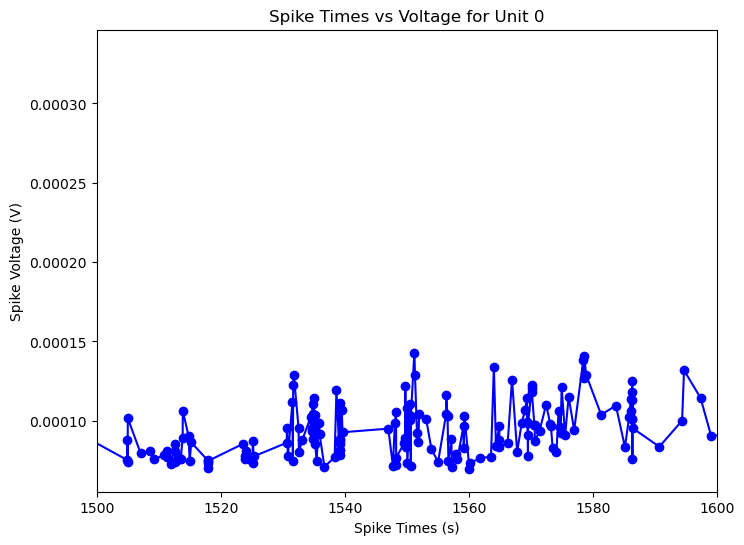

In [14]:
import matplotlib.pyplot as plt

i = 0
unit = all_units[i]

spike_times = unit["spike_times"]
spike_voltages = unit["spike_voltage"]

start_time = 1500
end_time = 1600

plt.figure(figsize=(8, 6))
plt.plot(spike_times, spike_voltages, marker='o', linestyle='-', color='b')

plt.xlim(start_time, end_time)

plt.title(f"Spike Times vs Voltage for Unit {i}")
plt.xlabel("Spike Times (s)")
plt.ylabel("Spike Voltage (V)")
